# Packaged SEMMA project
See report.md for consolidated results and README.md for reproduction. Earlier drafts retain their historical pending statements. Packaging restored the missing Sample Round 1 critique from the supplied conversation and fixed heading spacing; executed code and outputs are preserved.


# Student Grade Prediction Using SEMMA

## Phase 1 — Sample — Initial Draft

### Project objective
Predict the final mathematics grade, G3, using the student's earlier
grades, G1 and G2. This is a historical prediction demonstration,
not proof that the model improves student performance.

### Data source and selection
Source: https://www.kaggle.com/datasets/uciml/student-alcohol-consumption

I use student-mat.csv only. Each row represents a student record
for mathematics. The file contains 395 records and 33 columns.

G3 is the numeric target. G1 and G2 are the candidate predictors.
Using earlier grades gives this project a clear prediction point
after the second grading period. Other fields are excluded to
keep the model focused on prior academic performance.

### Sampling and partitioning
I retain all records because the dataset is small enough to process
in full. I use a reproducible random split: 60% training, 20%
validation, and 20% testing, with random_state=42.

Training data supports exploration and fitting. Validation data
supports model selection. Test data remains reserved for the final
assessment. This random split evaluates held-out historical
records; it does not establish performance for future cohorts.

### Planned assessment
The primary metric is mean absolute error (MAE), expressed in grade
points. Lower is better. Models will be compared with a baseline
that always predicts the training-set median grade.

The proposed success criterion is test MAE lower than the baseline.
This demonstrates predictive improvement, not a proven educational
benefit.

In [1]:
import io
import pandas as pd
from google.colab import files
from sklearn.model_selection import train_test_split

uploaded = files.upload()
df = pd.read_csv(io.BytesIO(uploaded["student-mat.csv"]))

assert {"G1", "G2", "G3"}.issubset(df.columns)

print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print(
    "Blank text values:",
    df.select_dtypes(include="object")
      .apply(lambda col: col.str.strip().eq("").sum())
      .sum()
)
print("Duplicate rows:", df.duplicated().sum())

display(df[["G1", "G2", "G3"]].agg(["min", "max"]))

train_df, remaining_df = train_test_split(
    df, test_size=0.40, random_state=42
)

val_df, test_df = train_test_split(
    remaining_df, test_size=0.50, random_state=42
)

assert set(train_df.index).isdisjoint(val_df.index)
assert set(train_df.index).isdisjoint(test_df.index)
assert set(val_df.index).isdisjoint(test_df.index)
assert len(train_df) + len(val_df) + len(test_df) == len(df)

display(pd.DataFrame({
    "Partition": ["Training", "Validation", "Test"],
    "Rows": [len(train_df), len(val_df), len(test_df)]
}))

print("Partition overlap and completeness checks passed.")

Saving student-mat.csv to student-mat.csv
Dataset shape: (395, 33)
Missing values: 0
Blank text values: 0
Duplicate rows: 0


,G1,G2,G3
min,3,0,0
max,19,19,20


,Partition,Rows
0,Training,237
1,Validation,79
2,Test,79


Partition overlap and completeness checks passed.


## Phase 1 — Sample — Critique Round 1

*Packaging note: this review was missing from the uploaded notebook. The following supplied review is restored from the project conversation, with table formatting normalized. It is not a new review.*

# SEMMA Phase 1 — Sample: Expert Review

Approved with minor corrections

Your Phase 1 draft meets the core requirements of SEMMA's Sample phase. The executed results support the dataset size, basic data-quality checks, and partition integrity.

There are two essential clarifications before finalizing this phase. No additional analysis or code changes are required.

## Review by requirement

| Requirement | Assessment | Issue and minimum correction |
|---|---|---|
| 1. Dataset source, records, predictors, target | Satisfied | The Kaggle source, mathematics file, 395 records, G1/G2 predictors, and G3 target are identified. No correction needed. |
| 2. Sample size and sampling approach | Satisfied | Retaining all 395 records is reasonable for a small historical dataset. The random partitioning approach is adequately justified. |
| 3. Training, validation, and test splits | Verified | The 237/79/79 split is consistent with 60/20/20. Index-overlap and completeness checks passed. No correction needed. |
| 4. Predictor availability | Clarification needed | The prediction point is identified, but the availability of G1 and G2 at that point should be stated as an assumption. |
| 5. Metric, baseline, success criterion | Defined | MAE, the training-median baseline, and the proposed test-MAE criterion are appropriate. Results remain pending. |
| 6. Representativeness and future performance | Clarification needed | You acknowledge that historical holdout performance does not establish future performance. Explicitly note that the sample is limited to the available mathematics records. |

## Essential corrections

### 1. Clarify predictor availability

Issue: You correctly describe a prediction made after the second grading period, but this does not independently verify operational availability of the earlier grades.

Minimum correction: Add one sentence to Data source and selection:

> The project assumes that G1 and G2 are finalized and available when the prediction is made, before G3 is known.

This establishes the temporal assumption without claiming it has been independently verified.

### 2. Clarify sample representativeness

Issue: The draft identifies the dataset and acknowledges limitations on future-cohort performance, but does not explicitly describe the limits of its population coverage.

Minimum correction: Add one sentence to Sampling and partitioning:

> The sample contains only the available mathematics student records and is not assumed to represent all students, schools, or future cohorts.

This adequately addresses the representativeness limitation without requiring additional sampling experiments.

## Verified results versus pending work

| Category | Findings |
|---|---|
| Verified through reported execution | 395 rows, 33 columns; zero pandas-recognized missing values, blank text values, and duplicate rows; grade ranges G1 = 3–19, G2 = 0–19, G3 = 0–20 |
| Verified partition checks | 237 training, 79 validation, and 79 test records; no index overlap; all records accounted for |
| Assumptions | G1 and G2 are available before G3; historical mathematics records are suitable for this demonstration |
| Defined but not yet evaluated | MAE, training-median baseline, and model-improvement criterion |
| Pending | Baseline MAE, model training, validation comparisons, and final held-out test MAE |

The reported checks establish basic dataset and split integrity. They do not establish model accuracy or future-cohort generalization.

## Final assessment

Phase 1 — Sample

Nearly complete

All six requirements are addressed. Two wording clarifications remain.

Required action: Add the two sentences above. Keep the existing code unchanged.

Once those corrections are incorporated, I would consider Phase 1 sufficiently documented for this assignment. You can then proceed to Phase 2 — Explore without adding optional work.


## Phase 1 — Sample — Revision 1

The initial draft is retained with these two clarifications:

**Predictor availability:** The project assumes that G1 and G2
are finalized and available when the prediction is made,
before G3 is known.

**Representativeness:** The sample contains only the available
mathematics student records and is not assumed to represent
all students, schools, or future cohorts.

The existing sampling procedure and executed checks remain
unchanged: 237 training, 79 validation, and 79 test records,
with no partition index overlap and all records accounted for.

Model training, baseline MAE, validation comparisons, and final
test performance remain pending.

## Phase 1 — Sample — Critique Round 2

# SEMMA Phase 1 — Sample: Revision 1 Review

&#x20;Approved — All concerns resolved

Revision 1 adequately addresses both concerns identified in Round 1. No additional corrections or analysis are required for Phase 1.

## Review of Round 1 concerns

| Concern                      | Status   | Assessment                                                                                                                                                 |
| ---------------------------- | -------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 1. Predictor availability    | Resolved | Explicitly assumes G1 and G2 are finalized and available before G3 is known. Correctly presents availability as an assumption rather than a verified fact. |
| 2. Sample representativeness | Resolved | Clearly limits the sample to available mathematics student records and avoids unsupported generalizations to other students, schools, or future cohorts.   |

## Verification status

- Previously verified: 395 records, 33 columns, basic data-quality checks, and 237/79/79 partition sizes with no index overlap.
- Assumed: G1 and G2 are available at the intended prediction point.
- Pending: Model training, baseline MAE, validation comparisons, and final test performance.
- New execution: None. Revision 1 introduces documentation clarifications only.

## Final assessment

Phase 1 — Sample: COMPLETE

Both Round 1 concerns are resolved. The sampling approach, partition roles, evaluation plan, and limitations are adequately documented for this assignment.

Essential corrections remaining: None.

Next step: Proceed to Phase 2 — Explore.

## Phase 1 — Sample — Final Revision

Revision 1 is adopted as final. Round 2 identified no remaining
essential corrections.

## Phase 2 — Explore — Initial Draft

I will explore G1, G2, and G3 using only the 237 training records.
Validation and test records remain reserved for their defined roles.

The exploration will examine grade distributions, unusual values,
and relationships between earlier grades and the final grade.
Summary statistics, zero counts, histograms, scatterplots, and
Pearson correlations will support these observations.

Zero grades will not automatically be treated as missing values
or removed. Any unusual observations require interpretation before
a preparation decision.

Observed relationships describe associations, not causal effects.
Model accuracy remains unverified until modeling and assessment.

,G1,G2,G3
count,237.00,237.00,237.00
mean,11.04,10.76,10.49
std,3.20,3.75,4.51
min,5.00,0.00,0.00
25%,9.00,9.00,9.00
50%,11.00,11.00,11.00
75%,13.00,13.00,13.00
max,19.00,19.00,20.00


,Zero grades,Outside 0–20
G1,0,0
G2,10,0
G3,23,0


,G1,G2,G3
G1,1.000,0.808,0.774
G2,0.808,1.000,0.908
G3,0.774,0.908,1.000


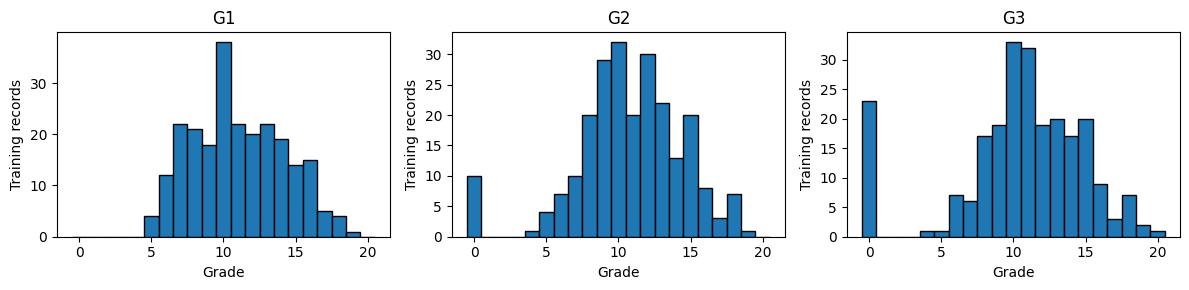

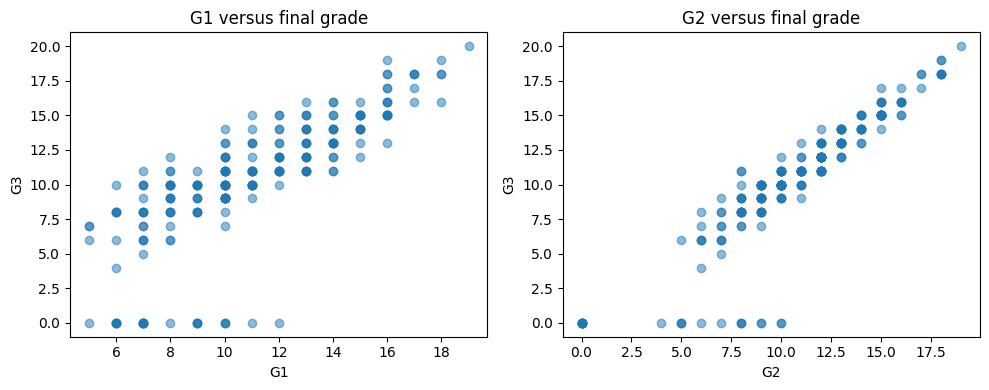

In [2]:
import matplotlib.pyplot as plt

grade_columns = ["G1", "G2", "G3"]
training_grades = train_df[grade_columns]

display(training_grades.describe().round(2))

display(pd.DataFrame({
    "Zero grades": training_grades.eq(0).sum(),
    "Outside 0–20": (
        (training_grades < 0) | (training_grades > 20)
    ).sum()
}))

display(training_grades.corr().round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for column, ax in zip(grade_columns, axes):
    ax.hist(
        training_grades[column],
        bins=[x - 0.5 for x in range(22)],
        edgecolor="black"
    )
    ax.set_title(column)
    ax.set_xlabel("Grade")
    ax.set_ylabel("Training records")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for column, ax in zip(["G1", "G2"], axes):
    ax.scatter(
        training_grades[column],
        training_grades["G3"],
        alpha=0.5
    )
    ax.set_xlabel(column)
    ax.set_ylabel("G3")
    ax.set_title(f"{column} versus final grade")

plt.tight_layout()
plt.show()

### Phase 2 — Explore — Findings

The exploration used the 237 training records only.

All three grades have a median of 11 and an interquartile range
from 9 to 13. Mean grades are 11.04 for G1, 10.76 for G2, and
10.49 for G3. G3 has the largest standard deviation, at 4.51.

No training grades fall outside 0–20. There are no zero values
in G1, 10 in G2, and 23 in G3. The histograms show a separate
concentration at zero for G2 and G3. These values will be
retained because the checks do not establish that they are
errors or missing-value codes. Their underlying reason remains
unverified.

Pearson correlations with G3 are 0.774 for G1 and 0.908 for G2.
G1 and G2 are also correlated with each other at 0.808.
G2 therefore has the stronger individual linear association
with the target in this training sample. These correlations
do not establish causation or held-out predictive accuracy.

Both planned predictors will be retained for modeling.
Validation will assess their combined predictive usefulness.
No records or values were changed during exploration.

## Phase 2 — Explore — Critique Round 1

# SEMMA Phase 2 — Explore: Expert Review

&#x20;Approved — No essential corrections

Your Phase 2 draft, findings, code, and execution outputs adequately satisfy the five review requirements. The reported statistics are consistent with the screenshots, and the conclusions stay within the assignment's scope.

## Review by requirement

| Requirement                         | Status    | Assessment                                                                                                                                                         |
| ----------------------------------- | --------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| 1. Training records only            | Satisfied | Code uses `train_df` exclusively. All reported statistics and visualizations are based on 237 training records.                                                    |
| 2. Distributions and unusual values | Satisfied | Means, medians, standard deviations, grade ranges, zero counts, and histograms are adequately described. The concentration of zero grades is correctly identified. |
| 3. Correlation interpretation       | Satisfied | Reported correlations match the output. G2's stronger linear association with G3 is correctly identified without claiming causation or predictive accuracy.        |
| 4. Retaining zero grades            | Satisfied | Retaining zeros is appropriately justified because their meaning has not been verified. No unsupported explanation is introduced.                                  |
| 5. Preparation readiness            | Satisfied | Both predictors are retained, no data modifications are made, and model performance remains explicitly unverified.                                                 |

## Verification status

| Category              | Findings                                                                                            |
| --------------------- | --------------------------------------------------------------------------------------------------- |
| Verified by execution | 237 training records; medians of 11; zero counts of 0, 10, and 23; no grades outside 0–20           |
| Verified correlations | G1–G3: 0.774; G2–G3: 0.908; G1–G2: 0.808                                                            |
| Unverified            | Reasons for zero grades and whether observed associations translate to held-out predictive accuracy |
| Pending               | Data preparation, model training, validation comparisons, and final test evaluation                 |

## Final assessment

Phase 2 — Explore: COMPLETE

- All five requirements are satisfied.
- Findings are supported by the executed outputs.
- No data leakage is evident in the exploration code.
- No additional analysis is necessary.

Essential corrections remaining: None.

Next step: Proceed to Phase 3 — Modify, retaining G1 and G2 as predictors and G3 as the target.

## Phase 2 — Explore — Revision 1

The initial draft and findings are retained unchanged following
Round 1, which identified no essential corrections.

Exploration used only the 237 training records. G1 and G2 remain
the planned predictors, with G3 as the target. Zero grades are
retained because their presence alone does not establish an error
or missing-value code; their underlying meaning remains unverified.

No additional analysis or data modifications were performed.
Held-out predictive performance remains pending.

## Phase 2 — Explore — Critique Round 2

# SEMMA Phase 2 — Explore: Revision 1 Review

&#x20;Approved — All requirements satisfied

Revision 1 retains the previously approved analysis and findings. No essential issues remain.

| Requirement                            | Status   | Assessment                                                                                               |
| -------------------------------------- | -------- | -------------------------------------------------------------------------------------------------------- |
| Training-only exploration              | Resolved | All exploration uses the 237 training records.                                                           |
| Grade distributions and unusual values | Resolved | Statistics, histograms, and zero counts were adequately documented in Round 1.                           |
| Correlation interpretation             | Resolved | Associations are correctly interpreted without causal claims.                                            |
| Zero-grade handling                    | Resolved | Retention is justified without assuming the meaning of zero values.                                      |
| Preparation readiness                  | Resolved | G1 and G2 remain predictors, G3 remains the target, and predictive performance is explicitly unverified. |

## Final assessment

Phase 2 — Explore: COMPLETE

- Verified previously: Training-only statistics, grade distributions, correlations, and zero counts.
- Unverified: Underlying meaning of zero grades and held-out predictive performance.
- New analysis: None, as correctly documented.
- Essential corrections remaining: None.

Next step: Proceed to Phase 3 — Modify.

No additional exploration or revisions are necessary for this assignment.

## Phase 2 — Explore — Final Revision

Revision 1 is adopted as final. Round 2 identified no essential
corrections.

## Phase 3 — Modify — Initial Draft

### Select and separate variables
I select G1 and G2 as predictors and separate G3 as the numeric
target. All other columns are excluded from modeling. The original
training, validation, and test partitions remain unchanged.

### Clean and format
The selected grades will be checked for numeric, finite values
within 0–20 and converted to floating-point format. Zero grades
are retained. No rows are removed.

No imputation is needed because the selected fields contain no
missing values. No categorical encoding is needed because both
predictors are numeric.

### Transformation decisions
G1 and G2 use the same grade scale. I retain their original units
for the planned Linear Regression and Random Forest comparison.
No scaling, binning, or derived features are introduced.

These preparation steps do not learn statistics from any partition.
Model fitting will use training data only.

### Verification
Checks will confirm predictor order, target exclusion, row alignment,
unchanged values, and valid numeric inputs in each partition.
These are structural checks, not an assessment of test performance.

In [3]:
import numpy as np

feature_columns = ["G1", "G2"]
target_column = "G3"

def prepare_partition(partition):
    grades = partition[feature_columns + [target_column]].apply(
        pd.to_numeric, errors="raise"
    )

    assert np.isfinite(grades.to_numpy()).all()
    assert grades.ge(0).all().all()
    assert grades.le(20).all().all()

    X = grades[feature_columns].astype(float).copy()
    y = grades[target_column].astype(float).copy()

    assert X.columns.tolist() == feature_columns
    assert target_column not in X.columns
    assert X.index.equals(y.index)
    assert X.index.equals(partition.index)
    assert np.array_equal(
        X.to_numpy(), partition[feature_columns].to_numpy()
    )
    assert np.array_equal(
        y.to_numpy(), partition[target_column].to_numpy()
    )

    return X, y

X_train, y_train = prepare_partition(train_df)
X_val, y_val = prepare_partition(val_df)
X_test, y_test = prepare_partition(test_df)

display(pd.DataFrame([
    {
        "Partition": name,
        "Rows": len(X),
        "Predictors": X.shape[1],
        "Missing values": int(X.isna().sum().sum() + y.isna().sum()),
        "Rows aligned": X.index.equals(y.index)
    }
    for name, X, y in [
        ("Training", X_train, y_train),
        ("Validation", X_val, y_val),
        ("Test", X_test, y_test)
    ]
]))

print("Predictor order:", feature_columns)
print("Target:", target_column)
print("Numeric validity, target exclusion, and unchanged-value checks passed.")

,Partition,Rows,Predictors,Missing values,Rows aligned
0,Training,237,2,0,True
1,Validation,79,2,0,True
2,Test,79,2,0,True


Predictor order: ['G1', 'G2']
Target: G3
Numeric validity, target exclusion, and unchanged-value checks passed.


### Phase 3 — Modify — Results

Preparation preserved 237 training, 79 validation, and 79 test
records. Each predictor matrix contains G1 and G2 in that order,
with G3 stored separately as the target.

All selected values are numeric, finite, and within 0–20.
No missing values were found. Row indices remain aligned,
and checks confirmed that conversion to floating-point format
did not change the grade values.

No records were removed, zeros were retained, and no learned
transformations were fitted. Model training and performance
evaluation remain pending.

## Phase 3 — Modify — Critique Round 1

# SEMMA Phase 3 — Modify: Expert Review

&#x20;Approved — No essential corrections

Your Phase 3 draft, code, and reported execution results adequately satisfy all five requirements. The preparation steps are appropriate for the planned models and preserve the original data.

## Review by requirement

| Requirement                                   | Status    | Assessment                                                                                                                                                         |
| --------------------------------------------- | --------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| 1. Predictor and target selection             | Satisfied | G1 and G2 are correctly selected as predictors, with G3 stored separately. The code explicitly checks target exclusion and predictor order.                        |
| 2. Numeric conversion and alignment           | Satisfied | Conversion to floating point preserves grade values, row counts, and index alignment according to the reported checks.                                             |
| 3. Zero grades, imputation, and encoding      | Satisfied | Retaining zeros is justified by Phase 2. No imputation or categorical encoding is necessary because the selected fields are numeric and contain no missing values. |
| 4. Original grade scale                       | Satisfied | Keeping G1 and G2 on their original 0–20 scale is appropriate for Linear Regression and Random Forest. Scaling is not required for this comparison.                |
| 5. Partition integrity and leakage prevention | Satisfied | All partitions are prepared independently without fitting transformations. No validation or test statistics are learned during preparation.                        |

## Verification status

| Category                        | Findings                                                                                        |
| ------------------------------- | ----------------------------------------------------------------------------------------------- |
| Reported executed checks        | 237 training, 79 validation, 79 test records; two predictors per partition; zero missing values |
| Verified by reported assertions | Numeric validity, unchanged values, predictor order, target exclusion, and row alignment        |
| Preparation decisions           | Zeros retained; no imputation, encoding, scaling, or feature engineering                        |
| Pending                         | Model fitting, validation comparisons, and final test performance                               |

## Final assessment

Phase 3 — Modify: COMPLETE

- All five requirements are satisfied.
- Preparation is consistent with the approved Sample and Explore phases.
- No data leakage is evident in the provided preparation code.
- No additional transformations or analysis are necessary.

Essential corrections remaining: None.

Next step: Proceed to Phase 4 — Model, training Linear Regression and Random Forest using the training partition and comparing their validation performance.

## Phase 3 — Modify — Revision 1

The initial draft, preparation code, and results are retained
unchanged following Round 1, which identified no essential corrections.

G1 and G2 remain the predictors, and G3 remains the separate target.
Preparation preserved grade values, row alignment, and partition
sizes. Zero grades were retained, and no learned transformations
were fitted.

No additional execution or modifications were performed.
Model fitting and performance evaluation remain pending.

## Phase 3 — Modify — Critique Round 2

# SEMMA Phase 3 — Modify: Revision 1 Review

&#x20;Approved — All requirements satisfied

Revision 1 retains the previously approved preparation code and results. All five requirements remain satisfied, and no essential issues remain.

| Requirement                                | Status   | Assessment                                                                                 |
| ------------------------------------------ | -------- | ------------------------------------------------------------------------------------------ |
| Predictor and target selection             | Resolved | G1 and G2 remain predictors, with G3 correctly excluded and stored separately.             |
| Numeric conversion and alignment           | Resolved | Previously executed checks confirmed unchanged values, row alignment, and partition sizes. |
| Zero grades, imputation, and encoding      | Resolved | Zero retention is justified. No imputation or categorical encoding is required.            |
| Original grade scale                       | Resolved | The original 0–20 scale remains appropriate for Linear Regression and Random Forest.       |
| Partition integrity and leakage prevention | Resolved | Partitions remain separate, and no learned transformations were fitted.                    |

## Final assessment

Phase 3 — Modify: COMPLETE

- Previously verified: Numeric validity, target exclusion, unchanged values, row alignment, and partition sizes (237/79/79).
- New execution: None, as correctly documented.
- Pending: Model fitting, validation comparisons, and final test evaluation.
- Essential corrections remaining: None.

Next step: Proceed to Phase 4 — Model.

No additional preparation or revisions are necessary for this assignment.

## Phase 3 — Modify — Final Revision

Revision 1 is adopted as final. Round 2 identified no essential
corrections.

## Phase 4 — Model — Initial Draft

### Modeling techniques
I compare Linear Regression and Random Forest regression using
G1 and G2 to predict G3.

Linear Regression models a linear relationship between earlier
and final grades. Random Forest can capture nonlinear relationships.

The baseline always predicts the median training G3 grade.
All three estimators are fitted using training records only.

### Model settings
Linear Regression uses its default settings. Random Forest uses
100 trees, max_depth=4, min_samples_leaf=5, and random_state=42.
The depth and leaf-size limits restrict model complexity.
These settings are fixed before examining validation results.
Full parameters and the scikit-learn version are recorded below.

### Comparison and selection
The primary metric is validation mean absolute error (MAE),
measured in grade points. Lower MAE is better.

The predictive model with the lowest validation MAE will be
selected. An exact tie favors Linear Regression for simplicity.
Its MAE will also be compared with the training-median baseline.

Predictions will remain continuous and will not be rounded or
clipped for evaluation. Linear Regression can produce predictions
outside 0–20; their count will be reported.

### Final fitting procedure
The selected model will retain its existing training-only fit
for final testing. No refitting or hyperparameter tuning is planned.
The test set will not be scored during this phase.

In [4]:
import sklearn
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

models = {
    "Median baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=4,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )
}

print("scikit-learn version:", sklearn.__version__)

validation_predictions = {}
results = []

assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions = pd.Series(
        model.predict(X_val),
        index=X_val.index,
        name="Predicted G3"
    )

    assert predictions.index.equals(y_val.index)
    assert len(predictions) == len(y_val)
    assert np.isfinite(predictions.to_numpy()).all()

    mae = mean_absolute_error(y_val, predictions)
    manual_mae = np.abs(
        y_val.to_numpy() - predictions.to_numpy()
    ).mean()
    assert np.isclose(mae, manual_mae)

    validation_predictions[name] = predictions
    results.append({
        "Model": name,
        "Validation MAE": mae,
        "Predictions outside 0–20": int(
            ((predictions < 0) | (predictions > 20)).sum()
        )
    })

    print(f"\n{name} parameters:")
    print(model.get_params())

assert np.allclose(
    validation_predictions["Median baseline"],
    y_train.median()
)

validation_results = pd.DataFrame(results)
display(validation_results.round(4))

candidate_names = ["Linear Regression", "Random Forest"]
mae_by_model = validation_results.set_index("Model")["Validation MAE"]

best_model_name = min(
    candidate_names,
    key=lambda name: (
        mae_by_model[name],
        candidate_names.index(name)
    )
)
best_model = models[best_model_name]

print("Training median:", y_train.median())
print("Selected model:", best_model_name)
print(
    "Beats validation baseline:",
    mae_by_model[best_model_name] < mae_by_model["Median baseline"]
)
print("Prediction alignment, finiteness, and manual MAE checks passed.")
print("Test set has not been scored.")

scikit-learn version: 1.6.1

Median baseline parameters:
{'constant': None, 'quantile': None, 'strategy': 'median'}

Linear Regression parameters:
{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}

Random Forest parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 4, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


,Model,Validation MAE,Predictions outside 0–20
0,Median baseline,3.3165,0
1,Linear Regression,1.0949,1
2,Random Forest,1.3107,0


Training median: 11.0
Selected model: Linear Regression
Beats validation baseline: True
Prediction alignment, finiteness, and manual MAE checks passed.
Test set has not been scored.


### Phase 4 — Model — Results

All three estimators were fitted on the 237 training records
and evaluated on the 79 validation records using scikit-learn 1.6.1.
Full estimator parameters are recorded alongside the output.

The baseline predicts the training median grade of 11.
Validation MAE was:
- Median baseline: 3.3165 grade points.
- Linear Regression: 1.0949 grade points.
- Random Forest: 1.3107 grade points.

Linear Regression achieved the lowest validation MAE and was
selected according to the predefined rule. Both predictive
models outperformed the median baseline on validation.

Linear Regression produced one prediction outside 0–20.
Predictions were neither rounded nor clipped, consistent with
the evaluation policy. This shows that its outputs are not
guaranteed to remain within the grade scale.

Prediction alignment, finiteness, baseline-median agreement,
and manual MAE checks passed.

The selected Linear Regression retains its training-only fit.
The test set has not been scored. Final success and performance
on future student cohorts remain unverified.

## Phase 4 — Model — Critique Round 1

# SEMMA Phase 4 — Model: Expert Review

&#x20;Approved — No essential corrections

Your Phase 4 draft, code, and reported execution results adequately satisfy all six requirements. Model selection follows the defined validation procedure, and final testing remains untouched.

## Review by requirement

| Requirement                           | Status    | Assessment                                                                                                                                      |
| ------------------------------------- | --------- | ----------------------------------------------------------------------------------------------------------------------------------------------- |
| 1. Models, parameters, and version    | Satisfied | Both models, the baseline, full estimator parameters, and scikit-learn version 1.6.1 are documented.                                            |
| 2. Training-only fitting              | Satisfied | All three estimators are fitted using `X_train` and `y_train` only. The baseline correctly uses the training median of 11.                      |
| 3. Validation-based selection         | Satisfied | Linear Regression has the lowest validation MAE (1.0949), outperforming Random Forest (1.3107) and the baseline (3.3165). Selection is correct. |
| 4. Prediction and metric verification | Satisfied | Index alignment, prediction length, finiteness, and manual MAE calculations are checked through assertions.                                     |
| 5. Out-of-range predictions           | Satisfied | One Linear Regression prediction falls outside 0–20. It is counted, and predictions remain unrounded and unclipped as predefined.               |
| 6. Final fitting procedure            | Satisfied | The selected training-fitted Linear Regression object is retained without refitting. The test set has not been scored.                          |

## Verified validation results

| Model             | Validation MAE | Outside 0–20 |
| ----------------- | -------------- | ------------ |
| Median baseline   | 3.3165         | 0            |
| Linear Regression | 1.0949         | 1            |
| Random Forest     | 1.3107         | 0            |

Values are from the supplied execution output; no independent rerun was performed.

## Final assessment

Phase 4 — Model: COMPLETE

- Selected model: Linear Regression.
- Verified by reported execution: Model comparison, prediction alignment, manual MAE consistency, and out-of-range prediction count.
- Pending: Final held-out test evaluation.
- Essential corrections remaining: None.

Next step: Proceed to Phase 5 — Assess, evaluating the retained Linear Regression model against the training-median baseline on the untouched test set.

No additional modeling or revisions are necessary for this assignment.

## Phase 4 — Model — Revision 1

The initial draft, modeling code, and results are retained unchanged
following Round 1, which identified no essential corrections.

Linear Regression remains selected based on its lowest validation
MAE of 1.0949, compared with 1.3107 for Random Forest and 3.3165
for the training-median baseline.

The selected model retains its training-only fit. Predictions remain
continuous, unrounded, and unclipped. The single out-of-range
validation prediction remains documented.

No additional fitting, tuning, or evaluation was performed.
Final test performance remains pending.

## Phase 4 — Model — Critique Round 2

# SEMMA Phase 4 — Model: Revision 1 Review

&#x20;Approved — All requirements satisfied

Revision 1 retains the previously approved modeling code, results, and selection decision. All six requirements remain satisfied, and no essential issues remain.

| Requirement                            | Status   | Assessment                                                                                  |
| -------------------------------------- | -------- | ------------------------------------------------------------------------------------------- |
| Model choices, parameters, and version | Resolved | Both models, full parameters, baseline, and scikit-learn version 1.6.1 remain documented.   |
| Training-only fitting                  | Resolved | All estimators were fitted exclusively on training data.                                    |
| Validation-based selection             | Resolved | Linear Regression correctly remains selected with the lowest validation MAE of 1.0949.      |
| Prediction and metric verification     | Resolved | Previously executed alignment, finiteness, and manual MAE checks passed.                    |
| Out-of-range prediction handling       | Resolved | The single out-of-range prediction remains documented. No rounding or clipping was applied. |
| Final fitting and test separation      | Resolved | The selected training-only fit is retained, and final test evaluation remains pending.      |

## Final assessment

Phase 4 — Model: COMPLETE

- Previously verified: Validation results, model selection, prediction alignment, and metric consistency.
- Selected model: Linear Regression.
- New execution: None, as correctly documented.
- Pending: Final held-out test evaluation.
- Essential corrections remaining: None.

Next step: Proceed to Phase 5 — Assess.

No additional modeling, tuning, or revisions are necessary for this assignment.

## Phase 4 — Model — Final Revision

Revision 1 is adopted as final. Round 2 identified no essential
corrections.

## Phase 5 — Assess — Initial Draft

### Final evaluation
I evaluate the selected training-fitted Linear Regression model
against the training-median baseline on the 79 held-out test records.
Neither estimator is refitted.

The primary metric is mean absolute error (MAE), measured in grade
points. The predefined success criterion is model test MAE lower
than baseline test MAE.

### Verification and interpretation
Predictions remain continuous, unrounded, and unclipped.
Checks will verify row alignment, finite predictions, and agreement
between the metric function and a manual MAE calculation.
Predictions outside 0–20 will be counted.

The assessment will report the absolute and percentage reduction
in MAE compared with the baseline. Validation and test MAE will
also be compared without assuming that any difference proves
overfitting.

### Limitations and next steps
Results describe this historical test sample. They do not establish
future-cohort accuracy or improved educational outcomes. The sample
is small, predictor availability is assumed, and the meaning of
zero grades remains unverified.

The model will not be changed in response to test results.
After assessment, I will save the model and demonstrate prediction
from G1 and G2 without requiring G3, then package the artifacts.

In [5]:
assert best_model_name == "Linear Regression"
assert X_test.index.equals(y_test.index)

test_predictions = pd.Series(
    best_model.predict(X_test),
    index=X_test.index,
    name="Predicted G3"
)

baseline_test_predictions = pd.Series(
    models["Median baseline"].predict(X_test),
    index=X_test.index,
    name="Baseline prediction"
)

test_rows = []

for name, predictions in [
    (best_model_name, test_predictions),
    ("Median baseline", baseline_test_predictions)
]:
    assert predictions.index.equals(y_test.index)
    assert len(predictions) == len(y_test)
    assert np.isfinite(predictions.to_numpy()).all()

    mae = mean_absolute_error(y_test, predictions)
    manual_mae = np.abs(
        y_test.to_numpy() - predictions.to_numpy()
    ).mean()
    assert np.isclose(mae, manual_mae)

    test_rows.append({
        "Model": name,
        "Test records": len(y_test),
        "Test MAE": mae,
        "Predictions outside 0–20": int(
            ((predictions < 0) | (predictions > 20)).sum()
        )
    })

assert np.allclose(baseline_test_predictions, y_train.median())

test_results = pd.DataFrame(test_rows)
display(test_results.round(4))

model_test_mae = mean_absolute_error(y_test, test_predictions)
baseline_test_mae = mean_absolute_error(
    y_test, baseline_test_predictions
)

mae_reduction = baseline_test_mae - model_test_mae
percentage_reduction = (
    100 * mae_reduction / baseline_test_mae
    if baseline_test_mae > 0 else np.nan
)

print("MAE reduction (grade points):", round(mae_reduction, 4))
print("MAE reduction (%):", round(percentage_reduction, 2))
print("Meets target:", model_test_mae < baseline_test_mae)
print("Selected model validation MAE:", round(
    mae_by_model[best_model_name], 4
))
print("Selected model test MAE:", round(model_test_mae, 4))
print("Alignment, finiteness, baseline, and manual MAE checks passed.")

,Model,Test records,Test MAE,Predictions outside 0–20
0,Linear Regression,79,1.3886,2
1,Median baseline,79,3.8608,0


MAE reduction (grade points): 2.4722
MAE reduction (%): 64.03
Meets target: True
Selected model validation MAE: 1.0949
Selected model test MAE: 1.3886
Alignment, finiteness, baseline, and manual MAE checks passed.


### Phase 5 — Assess — Results

The retained training-fitted Linear Regression model was evaluated
on 79 test records without refitting.

Test MAE was 1.3886 grade points, compared with 3.8608 for the
training-median baseline. This is a reduction of 2.4722 grade
points, or 64.03%. The predefined criterion of lower test MAE
than the baseline was met on this historical sample.

Model MAE increased from 1.0949 on validation to 1.3886 on test.
This single split does not establish the cause or statistical
significance of the difference and does not by itself prove
overfitting.

Two model predictions fell outside 0–20. Predictions remained
unrounded and unclipped under the predefined policy. The model
therefore does not guarantee outputs within the grade scale.

Alignment, finiteness, baseline-median agreement, and manual
MAE checks passed. These verify the reported implementation;
they do not establish future-cohort accuracy.

The model remains unchanged. Its historical performance supports
proceeding to the planned saved-model scoring demonstration.
Future performance and educational benefits remain unverified.
Model saving, the scoring demonstration, and final deliverables
remain pending.

## Phase 5 — Assess — Critique Round 1

# SEMMA Phase 5 — Assess: Expert Review

&#x20;Approved — No essential corrections

Your Phase 5 draft, code, and reported execution results adequately satisfy all five requirements. The final evaluation follows the predefined assessment procedure, and the conclusions are supported by the reported results.

## Review by requirement

| Requirement                                | Status    | Assessment                                                                                                                                                                   |
| ------------------------------------------ | --------- | ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 1. Test independence                       | Satisfied | The selected training-fitted Linear Regression model and median baseline are evaluated without refitting. No test-driven model changes are made.                             |
| 2. MAE reduction and success               | Satisfied | Test MAE of 1.3886 is lower than the baseline's 3.8608. The reported 2.4722-point reduction (64.03%) and success conclusion are consistent with full-precision calculations. |
| 3. Validation versus test                  | Satisfied | The increase from 1.0949 to 1.3886 MAE is correctly reported without claiming that the difference proves overfitting.                                                        |
| 4. Out-of-range predictions                | Satisfied | Two predictions outside 0–20 are documented. The predefined no-rounding/no-clipping policy is applied consistently.                                                          |
| 5. Verification, limitations, and delivery | Satisfied | Implementation checks, historical-sample limitations, and pending model-saving and delivery tasks are clearly distinguished.                                                 |

## Verified test results

| Metric                   | Linear Regression | Median baseline |
| ------------------------ | ----------------- | --------------- |
| Test records             | 79                | 79              |
| Test MAE                 | 1.3886            | 3.8608          |
| Predictions outside 0–20 | 2                 | 0               |

MAE REDUCTION RELATIVE TO BASELINE

# 64.03%

2.4722 fewer grade points of mean absolute error on the historical test set.

Results are based on the supplied execution output; no independent rerun was performed.

## Final assessment

Phase 5 — Assess: COMPLETE

- Previously defined success criterion: Met.
- Reported checks: Alignment, finiteness, baseline consistency, and manual MAE verification passed.
- Limitations: Future-cohort accuracy and educational benefits remain unverified.
- Pending: Model saving, scoring demonstration, and final deliverables.
- Essential corrections remaining: None.

Next step: Proceed with the planned saved-model scoring demonstration and artifact packaging.

No additional evaluation or revisions are necessary for this assignment.

## Phase 5 — Assess — Revision 1

The initial draft, evaluation code, and results are retained
unchanged following Round 1, which identified no essential corrections.

Linear Regression achieved test MAE of 1.3886 versus 3.8608 for
the training-median baseline, a 64.03% reduction. The predefined
historical test criterion was met.

The two out-of-range predictions remain documented, with no
rounding or clipping applied. The model retains its training-only
fit; no test-driven changes or additional evaluations were performed.

Future-cohort accuracy and educational benefits remain unverified.
Model saving, the scoring demonstration, and final deliverables
remain pending.

## Phase 5 — Assess — Critique Round 2

## SEMMA Phase 5 — Assess: Revision 1 Review

&#x20;Approved — All requirements satisfied

Revision 1 retains the previously approved evaluation code, results, and conclusions. All five requirements remain satisfied, and no essential issues remain.

| Requirement                             | Status   | Assessment                                                                                                        |
| --------------------------------------- | -------- | ----------------------------------------------------------------------------------------------------------------- |
| Test independence                       | Resolved | The selected training-only model and baseline were evaluated without refitting or test-driven changes.            |
| MAE reduction and success               | Resolved | Test MAE of 1.3886 versus 3.8608 confirms the reported 64.03% reduction and meets the predefined criterion.       |
| Validation versus test                  | Resolved | The difference is appropriately documented without unsupported claims of overfitting.                             |
| Out-of-range predictions                | Resolved | Both out-of-range predictions remain documented. No rounding or clipping was applied.                             |
| Verification, limitations, and delivery | Resolved | Previously executed checks, historical-sample limitations, and pending deliverables remain clearly distinguished. |

## Final assessment

Phase 5 — Assess: COMPLETE

- Previously verified: Test MAE, baseline comparison, metric calculations, prediction alignment, and finiteness checks.
- New execution: None, as correctly documented.
- Unverified: Future-cohort accuracy and educational benefits.
- Pending: Model saving, scoring demonstration, and final deliverables.
- Essential corrections remaining: None.

Next step: Proceed with the saved-model scoring demonstration and final artifact packaging.

No additional evaluation or revisions are necessary for this assignment.

## Phase 5 — Assess — Final Revision

Revision 1 is adopted as final. Round 2 identified no essential
corrections.

## Delivery — Saved-Model Scoring Demonstration

I will save and reload the selected training-fitted Linear Regression
model, then score the historical test predictors without supplying G3.

The scoring function will require numeric, finite G1 and G2 values
within 0–20, preserve input row indices, and return continuous
predictions without rounding or clipping. Out-of-range predictions
will be flagged.

Reloaded predictions must match the original test predictions using
rtol=1e-9 and atol=1e-12.

The exported artifacts will include the fitted model, prediction
demonstration, validation and test results, input schema, and software
versions. This is a historical scoring demonstration, not an
operational student-support system.


In [6]:
from pathlib import Path
import json
import platform
import joblib

artifact_dir = Path("02_SEMMA/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)

model_path = artifact_dir / "grade_model.joblib"
joblib.dump(best_model, model_path)
loaded_model = joblib.load(model_path)


def score_students(accounts, model):
    required = ["G1", "G2"]

    if not set(required).issubset(accounts.columns):
        raise ValueError("Input must contain G1 and G2.")
    if accounts.empty:
        raise ValueError("Input must contain at least one record.")
    if not accounts.index.is_unique:
        raise ValueError("Input row indices must be unique.")

    predictors = accounts[required].apply(
        pd.to_numeric, errors="raise"
    ).astype(float)

    if not np.isfinite(predictors.to_numpy()).all():
        raise ValueError("Grades must be finite and nonmissing.")
    if not predictors.ge(0).all().all() or not predictors.le(20).all().all():
        raise ValueError("Input grades must be within 0–20.")

    predictions = model.predict(predictors)

    if not np.isfinite(predictions).all():
        raise ValueError("Model produced nonfinite predictions.")

    result = predictors.copy()
    result["Predicted G3"] = predictions
    result["Outside 0–20"] = (predictions < 0) | (predictions > 20)
    return result


demo_input = X_test.copy()
demo_predictions = score_students(demo_input, loaded_model)

assert "G3" not in demo_input.columns
assert demo_predictions.index.equals(test_predictions.index)

scores_match = np.allclose(
    demo_predictions["Predicted G3"].to_numpy(),
    test_predictions.to_numpy(),
    rtol=1e-9,
    atol=1e-12
)
assert scores_match

prediction_export = (
    demo_predictions.rename_axis("Source row index").reset_index()
)

exports = {
    "simulated_grade_predictions.csv": prediction_export,
    "validation_results.csv": validation_results,
    "test_results.csv": test_results
}

export_checks = []

for filename, expected in exports.items():
    path = artifact_dir / filename
    expected.to_csv(path, index=False)
    restored = pd.read_csv(path)

    pd.testing.assert_frame_equal(
        restored,
        expected.reset_index(drop=True),
        check_dtype=False,
        check_exact=False,
        rtol=1e-9,
        atol=1e-12
    )

    export_checks.append({
        "File": filename,
        "Rows": len(restored),
        "Matches notebook data": True
    })

schema = {
    "required_predictors": ["G1", "G2"],
    "input_type": "numeric, finite, nonmissing",
    "input_range": [0, 20],
    "target_required": False,
    "prediction_policy": "continuous, no rounding or clipping",
    "row_reference": "original DataFrame index; not a student identifier"
}

environment = {
    "python": platform.python_version(),
    "scikit-learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "joblib": joblib.__version__
}

for filename, content in [
    ("input_schema.json", schema),
    ("environment.json", environment)
]:
    path = artifact_dir / filename
    path.write_text(json.dumps(content, indent=2))
    assert json.loads(path.read_text()) == content

print("Saved model:", model_path)
print("Predictions reproduced after reload:", scores_match)
print("Scoring input contains G3:", "G3" in demo_input.columns)
print("Scored records:", len(demo_predictions))
print("Out-of-range predictions:", int(
    demo_predictions["Outside 0–20"].sum()
))
print("Schema and environment JSON checks passed.")

display(prediction_export.head())
display(pd.DataFrame(export_checks))

Saved model: 02_SEMMA/artifacts/grade_model.joblib
Predictions reproduced after reload: True
Scoring input contains G3: False
Scored records: 79
Out-of-range predictions: 2
Schema and environment JSON checks passed.


,Source row index,G1,G2,Predicted G3,Outside 0–20
0,153,5.0,0.0,-1.017101,True
1,93,11.0,10.0,9.748856,False
2,198,18.0,18.0,18.723584,False
3,366,13.0,13.0,13.011549,False
4,320,13.0,13.0,13.011549,False


,File,Rows,Matches notebook data
0,simulated_grade_predictions.csv,79,True
1,validation_results.csv,3,True
2,test_results.csv,2,True


### Delivery — Results

The selected model was saved to artifacts/grade_model.joblib.
After reloading, predictions matched the original test predictions
within rtol=1e-9 and atol=1e-12.

The demonstration scored 79 historical records using G1 and G2
without requiring G3. Row alignment was preserved. Two predictions
fell outside 0–20 and were flagged without rounding or clipping.
Source row indices identify notebook records, not individual students.

All three CSV exports were reloaded and matched the notebook data:
- simulated_grade_predictions.csv: 79 rows.
- validation_results.csv: 3 rows.
- test_results.csv: 2 rows.

Input-schema and environment JSON checks also passed.
Scoring requires the saved model and the score_students function,
which validates and formats inputs before prediction.

This project implements SEMMA in Python/Colab; SAS was not used.
The demonstration does not establish future-cohort accuracy or
educational benefits.

The final report, GitHub publication, Medium article, and YouTube
walkthrough remain pending.

In [7]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/02_SEMMA_artifacts",
    "zip",
    root_dir="/content/02_SEMMA",
    base_dir="artifacts"
)

files.download("/content/02_SEMMA_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>